# 01 Data analysis: orbit-scan latency under a workload sweep

**Project:** Spacetime Dimensionality and Black-Hole Properties (Task 3).
**Question for this notebook:** how does the latency of the measured function (the circular-orbit stability scan) depend on the workload $N$ and on the spacetime dimension $D$, and how much of that is measurement noise?

Pipeline: raw `.jsonl` log, then warm-up filtering, error guardrail, outlier flags, statistics with bootstrap 95% CIs, figures. Reusable logic lives in `src/process_data.py` and `src/visualize.py`; this notebook calls it and shows every intermediate result. Run it with *Kernel, Restart & Run All*; all outputs are stored.

## 1. Setup and reproducibility
The seed is fixed (`numpy.random.seed(42)`); the bootstrap uses its own seeded generator from the config, so every interval below is reproducible.

In [1]:
import json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src import process_data, visualize

np.random.seed(42)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

cfg = process_data.load_config()
a = cfg["analysis"]
print("repo root:", ROOT.name, "| seed:", a["seed"], "| bootstrap resamples:", a["n_bootstrap"])
print("numpy", np.__version__, "| pandas", pd.__version__)

repo root: spacetime-dimensions-bh 2 | seed: 42 | bootstrap resamples: 2000
numpy 2.5.3 | pandas 3.0.5


## 2. Data ingestion
Each line of `data/raw/test_run.jsonl` is one timed run. The schema is validated on load (missing columns or unknown phase labels raise an error). Environment metadata was written by the collector next to the log.

In [2]:
raw = process_data.load_raw(a["raw"])
print("raw records:", len(raw))
display(raw.head())

meta = json.load(open("data/raw/run_metadata.json"))
keys = ["cpu_model", "cpu_count", "ram_gb", "platform", "python", "numpy", "scipy",
        "in_docker", "git_commit", "n_records", "n_cells"]
display(pd.Series({k: meta[k] for k in keys}, name="value").to_frame())

raw records: 2640


,run_id,ts_us,phase,family,D,n_grid,rep,latency_ms,ok,error
0,1,1794126307126137,warmup,orbit_scan,8,100000,0,7.2678,True,NaN
1,2,1794126307132713,warmup,orbit_scan,8,100000,1,6.5646,True,NaN
2,3,1794126307138506,warmup,orbit_scan,8,100000,2,5.7820,True,NaN
3,4,1794126307142962,warmup,orbit_scan,8,100000,3,4.4496,True,NaN
4,5,1794126307148989,warmup,orbit_scan,8,100000,4,6.0157,True,NaN


,value
cpu_model,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
cpu_count,12
ram_gb,None
platform,Windows-11-10.0.26200-SP0
python,3.13.3
numpy,2.5.3
scipy,1.18.1
in_docker,False
git_commit,476e63334907406cf63556cc7c2fd3fbaba82628
n_records,2640


## 3. Warm-up filtering
The first runs of a cell are slower (cold caches, first-time allocations). They are logged with `phase = "warmup"` and **discarded before any statistic**. The cell below also measures how large the cold-start effect actually was.

In [3]:
warm, bench = process_data.split_phases(raw)
print(f"warm-up runs discarded: {len(warm)}  |  benchmark runs kept: {len(bench)}")

first = warm[warm["rep"] == 0].set_index(["D", "n_grid"])["latency_ms"]
med = bench.groupby(["D", "n_grid"])["latency_ms"].median()
ratio = (first / med).dropna()
print(f"first warm-up run vs benchmark median, per cell: median x{ratio.median():.2f}, "
      f"range x{ratio.min():.2f} to x{ratio.max():.2f}")

warm-up runs discarded: 240  |  benchmark runs kept: 2400
first warm-up run vs benchmark median, per cell: median x1.55, range x0.92 to x4.10


## 4. Error guardrail
Failed runs are **not dropped to make the numbers look better**: the error rate is a guardrail metric reported per cell, and latency statistics use only successful runs.

In [4]:
err = bench.groupby(["D", "n_grid"])["ok"].apply(lambda s: 1 - s.mean())
print(f"overall error rate: {1 - bench['ok'].mean():.4%}  |  worst cell: {err.max():.4%}")
print("guardrail passed" if err.max() == 0 else "WARNING: failed runs present, inspect bench[~bench.ok]")

overall error rate: 0.0000%  |  worst cell: 0.0000%
guardrail passed


## 5. Outlier flags (non-destructive)
Spikes are flagged with Tukey fences ($1.5\times$ IQR per cell) but kept: from latency alone a real load spike cannot be told apart from scheduler noise, so deleting them would bias the tail percentiles.

In [5]:
bench = process_data.flag_outliers(bench, a["iqr_factor"])
print(f"runs flagged as outliers (kept in the data): {bench['is_outlier'].mean():.1%}")
display(bench.groupby("D")["is_outlier"].mean().rename("outlier fraction").to_frame().T.round(3))

runs flagged as outliers (kept in the data): 9.5%


D,4,5,6,7,8,9,10,11
outlier fraction,0.087,0.113,0.117,0.13,0.097,0.083,0.043,0.093


## 6. Statistical aggregation
Per cell $(D, N)$: mean, SD, median, p25, p75, p95, p99, and percentile-bootstrap 95% CIs of p50, p95 and p99. With 50 runs per cell the p99 estimate rests on the largest one or two runs, so its interval is wide; this is visible in Fig. 1b.

In [6]:
summary = process_data.aggregate(bench, a["n_bootstrap"], a["ci_level"], a["seed"])
phys = process_data.physics_summary(cfg)

for key, frame in (("processed", summary), ("physics_summary", phys)):
    Path(a[key]).parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(a[key], index=False, float_format="%.6g")
print("saved", a["processed"], summary.shape, "and", a["physics_summary"], phys.shape)

cols = ["D", "n_grid", "n_ok", "error_rate", "p50_ms", "p50_ci_low_ms", "p50_ci_high_ms", "p95_ms", "p99_ms"]
display(summary[summary["n_grid"] == a["box_n_grid"]][cols].round(4))

saved data/processed/metrics_summary.csv (48, 19) and data/processed/physics_summary.csv (8, 7)


,D,n_grid,n_ok,error_rate,p50_ms,p50_ci_low_ms,p50_ci_high_ms,p95_ms,p99_ms
3,4,20000,50,0.0,0.3362,0.3326,0.3401,0.5237,0.5600
9,5,20000,50,0.0,0.5276,0.5223,0.5385,0.7103,0.8104
15,6,20000,50,0.0,0.4885,0.4862,0.4911,0.5403,0.6378
21,7,20000,50,0.0,0.7504,0.7349,0.7951,1.1752,1.2236
27,8,20000,50,0.0,0.6855,0.6828,0.6884,0.7613,0.8624
33,9,20000,50,0.0,0.7139,0.7121,0.7192,0.8193,1.0713
39,10,20000,50,0.0,0.8410,0.7754,0.9011,1.2240,1.2430
45,11,20000,50,0.0,0.6832,0.6776,0.6894,0.8064,0.9675


## 7. Sanity checks on the statistics

In [7]:
inside = ((summary.p50_ms >= summary.p50_ci_low_ms) & (summary.p50_ms <= summary.p50_ci_high_ms)).mean()
print(f"median lies inside its own 95% CI in {inside:.0%} of cells")

by_n = summary.groupby("n_grid")["p50_ms"].median()
slope = np.polyfit(np.log(by_n.index.to_numpy()), np.log(by_n.to_numpy()), 1)[0]
print(f"log-log slope of median latency vs N: {slope:.2f}  (1.00 would be exactly linear in N)")

again = process_data.aggregate(bench, a["n_bootstrap"], a["ci_level"], a["seed"])
print("re-running the aggregation with the same seed gives identical output:", again.equals(summary))

median lies inside its own 95% CI in 100% of cells
log-log slope of median latency vs N: 0.99  (1.00 would be exactly linear in N)
re-running the aggregation with the same seed gives identical output: True


## 8. Figures
Both figures follow the three rules of scientific visualisation: labelled axes with units (log scales where values span orders of magnitude), 95% CI drawn on every estimate, colour-blind-safe palette with distinct markers and line styles. Each is exported as vector `.pdf` and as `.png` at 300 DPI into `reports/figures/`.

reports\figures\fig1_latency_vs_load.pdf
reports\figures\fig1_latency_vs_load.png
reports\figures\fig2_distribution_boxplot.pdf
reports\figures\fig2_distribution_boxplot.png


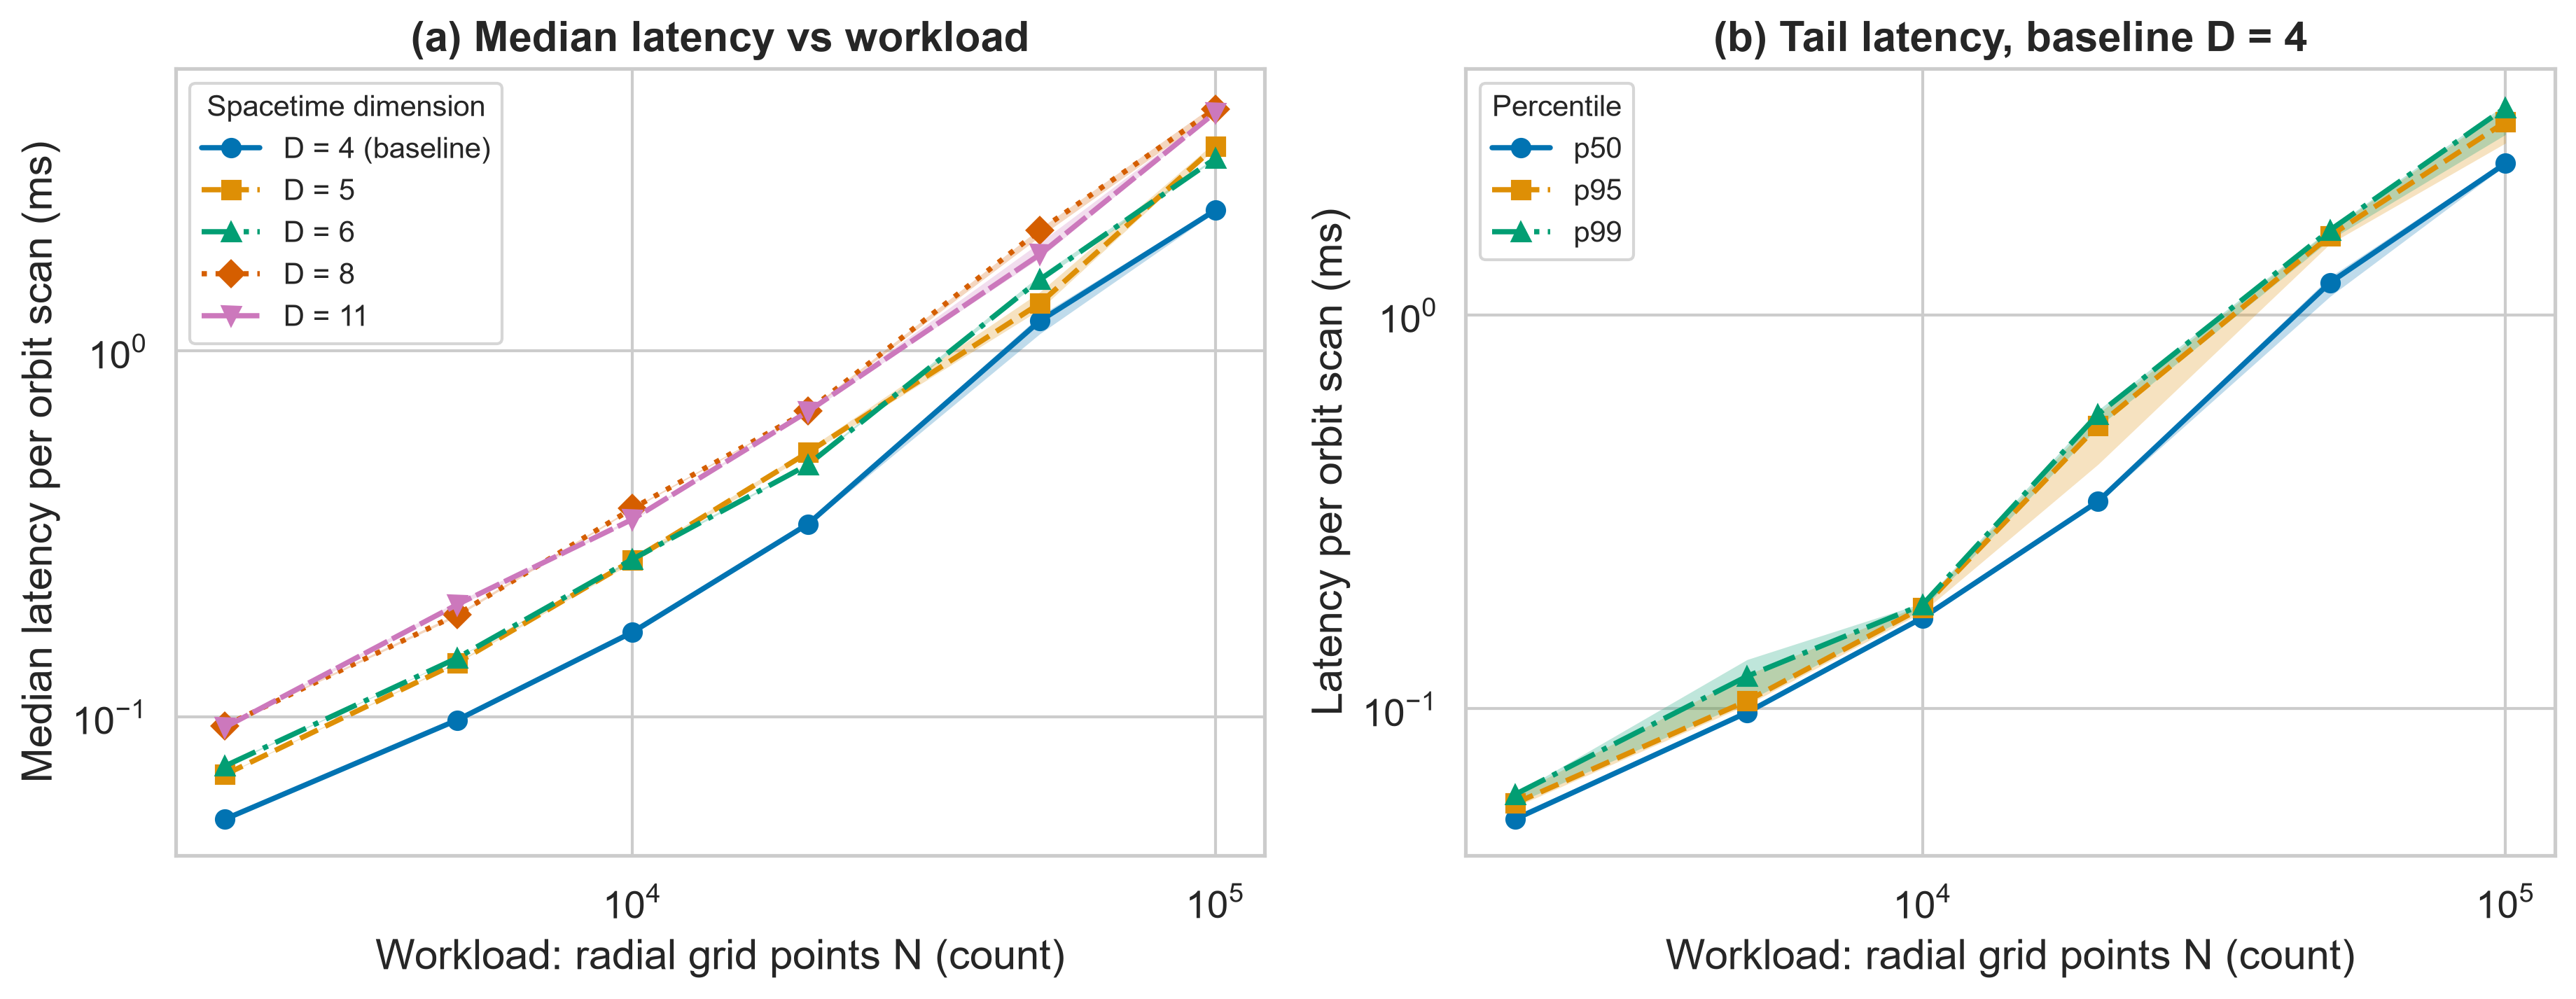

In [8]:
paths = visualize.make_all(cfg, summary, bench)
for p in paths:
    print(p)
display(Image(filename=str(paths[1]), width=900))

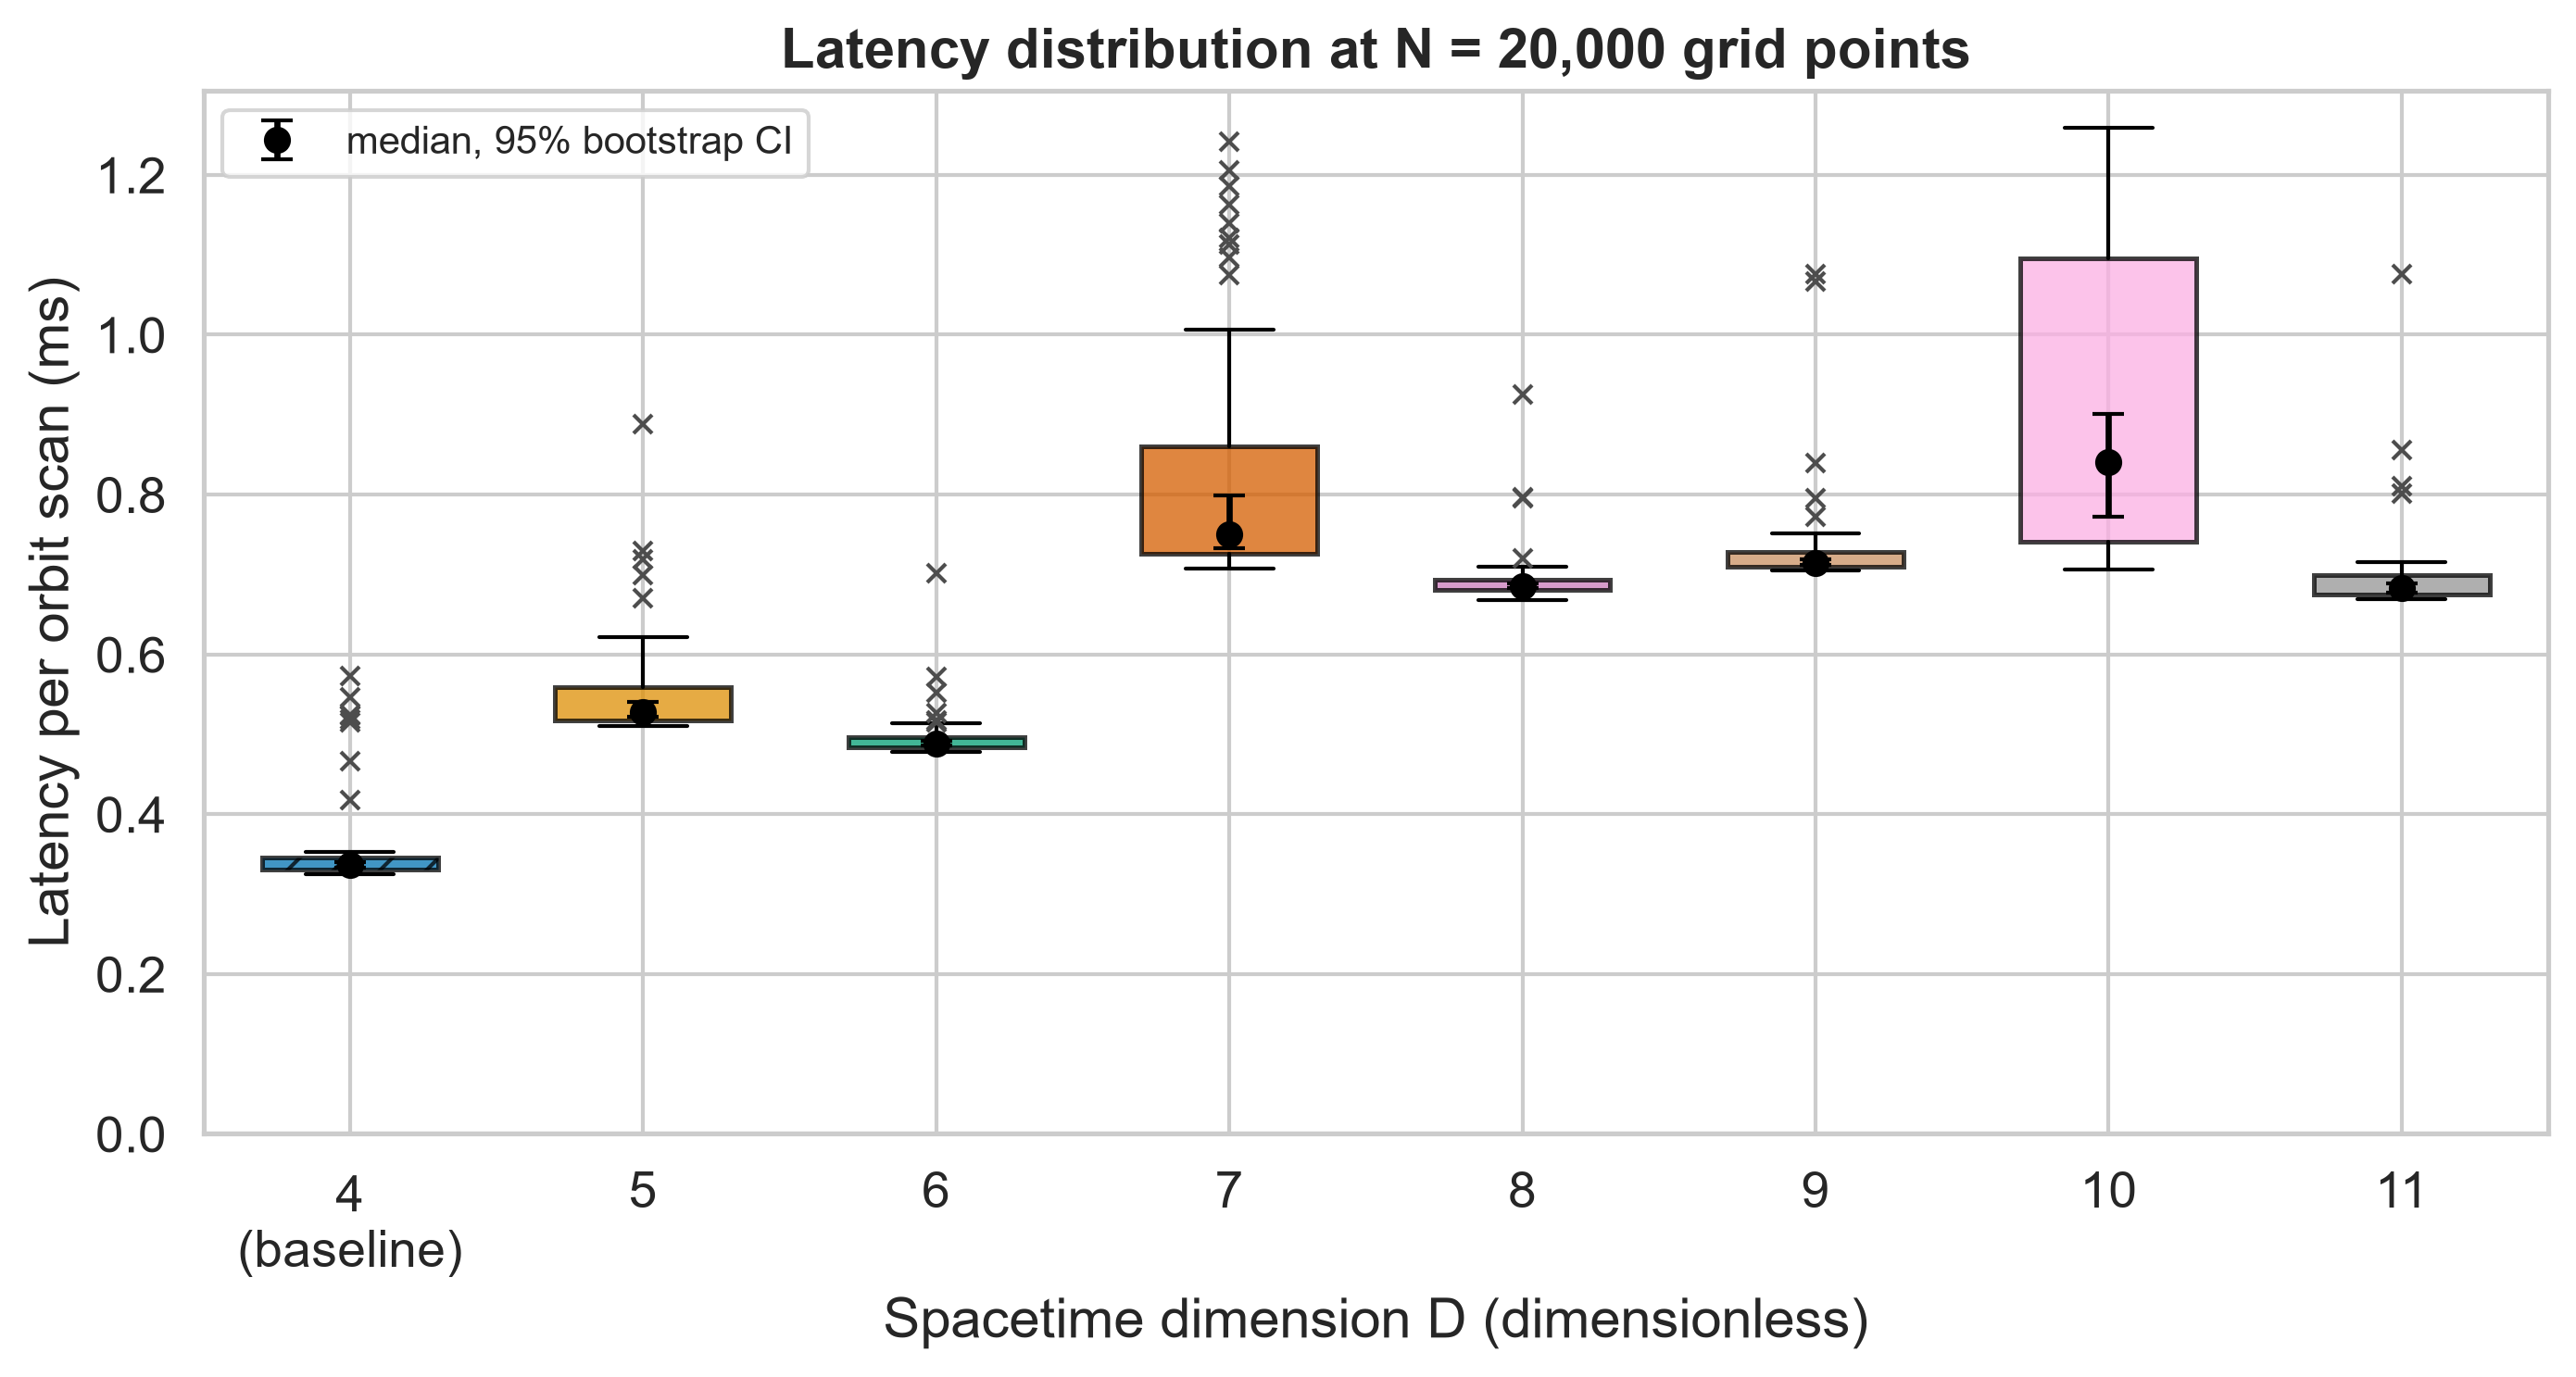

In [9]:
display(Image(filename=str(paths[3]), width=700))

## 9. Baseline versus the other dimensions

In [10]:
x = summary[summary["n_grid"] == a["box_n_grid"]].set_index("D")
table = pd.DataFrame({
    "median (p25-p75), ms": [f"{r.p50_ms:.3f} ({r.p25_ms:.3f}-{r.p75_ms:.3f})" for r in x.itertuples()],
    "p95, ms": x.p95_ms.round(3),
    "p99, ms": x.p99_ms.round(3),
    "median / baseline": (x.p50_ms / x.loc[4, "p50_ms"]).round(2),
    "error rate": x.error_rate.map("{:.1%}".format),
}, index=x.index)
display(table)

,"median (p25-p75), ms","p95, ms","p99, ms",median / baseline,error rate
D,,,,,
4,0.336 (0.331-0.345),0.524,0.560,1.00,0.0%
5,0.528 (0.517-0.559),0.710,0.810,1.57,0.0%
6,0.489 (0.484-0.496),0.540,0.638,1.45,0.0%
7,0.750 (0.725-0.860),1.175,1.224,2.23,0.0%
8,0.685 (0.681-0.694),0.761,0.862,2.04,0.0%
9,0.714 (0.709-0.729),0.819,1.071,2.12,0.0%
10,0.841 (0.741-1.095),1.224,1.243,2.50,0.0%
11,0.683 (0.675-0.700),0.806,0.968,2.03,0.0%


### Scientific result of the experiment (from the analytic solutions)
The latency study above measures the cost of the computation. The physics outcome that answers the research question is below: the primary metric $B(D)$ (horizon at $\chi = 4$) and the spin bound.

In [11]:
display(phys.round(4))

,D,B_horizon_at_chi_cap,chi_max_on_grid,r_ph_over_r_h,has_stable_circular_orbit,temperature_M1,entropy_M1
0,4,0,0.5,1.5000,True,0.0398,12.5664
1,5,0,1.0,1.4142,False,0.1727,3.8592
2,6,1,4.0,1.3572,False,0.3054,2.4554
3,7,1,4.0,1.3161,False,0.4218,1.8965
4,8,1,4.0,1.2847,False,0.5236,1.5914
5,9,1,4.0,1.2599,False,0.6140,1.3960
6,10,1,4.0,1.2397,False,0.6954,1.2583
7,11,1,4.0,1.2228,False,0.7697,1.1548


## 10. Discussion

Numbers refer to the committed run (Windows 11 PC, 12 logical CPUs, Python 3.13.3; see the metadata table in section 2). A re-run on other hardware will change the absolute values but not the method.

* **Warm-up matters.** The first warm-up run of a cell was on median 1.55 times slower than the benchmark median (range 0.92 to 4.1 times). Keeping those runs would have inflated the tail statistics.
* **No failed runs.** The error rate is 0% in every cell, so the latency statistics are not subject to selection bias in this run.
* **Workload scaling is close to linear.** The log-log slope of median latency against $N$ is about 0.99, i.e. latency grows almost proportionally to the number of grid points.
* **Dependence on $D$ is clear.** At $N = 20{,}000$ the baseline $D = 4$ has the smallest median (about 0.34 ms); other dimensions are 1.4 to 2.5 times slower, with the largest values at $D = 10$ and $D = 7$, which are also the noisiest cells (widest IQR and CI). The 95% CIs of the median do not overlap for any of the seven neighbouring pairs. We did not investigate the cause of this ordering, so it is reported as an observation, not an explanation.
* **Tails are light.** At $N = 20{,}000$ the p99 is a median of about 1.49 times the p50 (at most 1.67 times); 9.5% of all runs are flagged as outliers. Because p99 rests on one or two runs per cell, it is the least certain statistic here.
* **Physics outcome (unchanged from Task 2).** $B(4) = B(5) = 0$ and $B(D) = 1$ for $D \ge 6$: the spin bound disappears from $D = 6$ on, so $H_0$ is rejected by the primary metric; stable circular orbits exist only for $D = 4$. This confirms known analytic results and is not observational evidence for extra dimensions.

**Limitations.** One machine, one process, a personal Windows computer with other programs running (background noise cannot be excluded), a single measured function, and 50 runs per cell.